# 1 · De imágenes y sonidos a características
### Guía para comprender el proyecto y preparar el informe

**Objetivo:** entender qué representan los datos y por qué los preparamos antes de reconocer huellas y comandos. Este cuaderno recorre el comienzo del trabajo; el segundo explica PCA y huellas, y el tercero voz e integración.

La explicación distingue tres cosas: **qué necesitábamos resolver**, **qué significa cada concepto** y **cómo lo aplicamos**. Los gráficos quedan guardados para leer sin ejecutar. Las celdas de código producen figuras o tablas: no son una batería de verificaciones ni reentrenan el sistema.

## El problema completo

Queríamos un agente que recibiera una imagen de huella sintética y comandos de voz. Al oír **Reconocer**, debía evaluar si esa imagen correspondía a una de tres identidades autorizadas. Al oír **Identificar**, debía mostrar cuál, si antes había sido autorizada. Al oír **Salir**, debía concluir la ejecución.

La consigna determina K-means con tres grupos para huellas, una distancia y un umbral de rechazo, y K-NN para comandos. También pide un análisis PCA. No establece que haya que utilizar 144 o 160 características: esas dimensiones provienen de nuestras decisiones de representación.

No reconocemos quién habla. En audio, la clase es **la palabra**. En huellas, la clase autorizada es **la identidad sintética**. El agente combina los dos resultados, pero no mezcla sus vectores numéricos.

In [2]:
%pip install pandas

   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
   ------------- -------------------------- 3.7/10.9 MB 19.4 MB/s eta 0:00:01
   ------------------------------- -------- 8.7/10.9 MB 19.5 MB/s eta 0:00:01
   ---------------------------------------  10.7/10.9 MB 19.5 MB/s eta 0:00:01
   ---------------------------------------- 10.9/10.9 MB 12.2 MB/s  0:00:00

   ---------------------------------------- 0/2 [tzdata]
   ---------------------------------------- 0/2 [tzdata]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 


[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

# Ejecutar con la carpeta de estos notebooks como directorio de trabajo.
DATOS = Path("datos")
FIGURAS = Path("figuras")
plt.rcParams.update({"figure.figsize": (12, 5), "font.size": 12,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "figure.dpi": 110})
COLORES = {"A01": "#2563EB", "A02": "#0D9488", "A03": "#9333EA",
           "I01": "#DC2626", "I02": "#EA580C"}

## Identidad, base y captura no son lo mismo

Una **identidad** es la categoría que queremos reconocer, por ejemplo A01. Su **base** es el patrón maestro de huella. Una **captura** representa cómo se podría observar ese patrón en una toma concreta, con variación de contacto, pose, calidad o deformación.

Si creamos diez capturas desde A01, tenemos diez ejemplos de una misma identidad, no diez personas distintas. Y si guardamos el original y su versión normalizada, seguimos teniendo una sola observación con dos representaciones.

Las bases se obtuvieron con Anguli. Se trabajó con tres identidades autorizadas (A01–A03), dos intrusas de desarrollo (I01–I02) y dos intrusas reservadas (I03–I04). La palabra intruso no define una única identidad: I01 e I02 son distintas. En reconocimiento, ambas deben rechazarse.

Nuestro generador aplicó transformaciones a esas bases. Una rotación mueve la imagen como conjunto; una deformación no lineal desplaza diferentes zonas de forma distinta. Se buscó que el modelo viera variaciones de una identidad, no solo copias idénticas. También se simularon contacto, contraste, calidad y ruido. Las ampliaciones de entrenamiento incluyeron nuevas capturas y rotaciones hasta ±90° en el procedimiento documentado; eso no prueba tolerancia universal a cualquier giro o sensor.

### Semillas y reproducibilidad

La semilla fija una secuencia de números pseudoaleatorios. Permite repetir una generación si también conservamos el algoritmo, configuración, base y entorno pertinentes. La semilla de una identidad Anguli no es la misma que la semilla de una captura generada desde esa base. Ninguna se entrega al clasificador para decidir la identidad.

Una voz humana no se reproduce mediante una semilla. Su evidencia es la grabación original conservada.

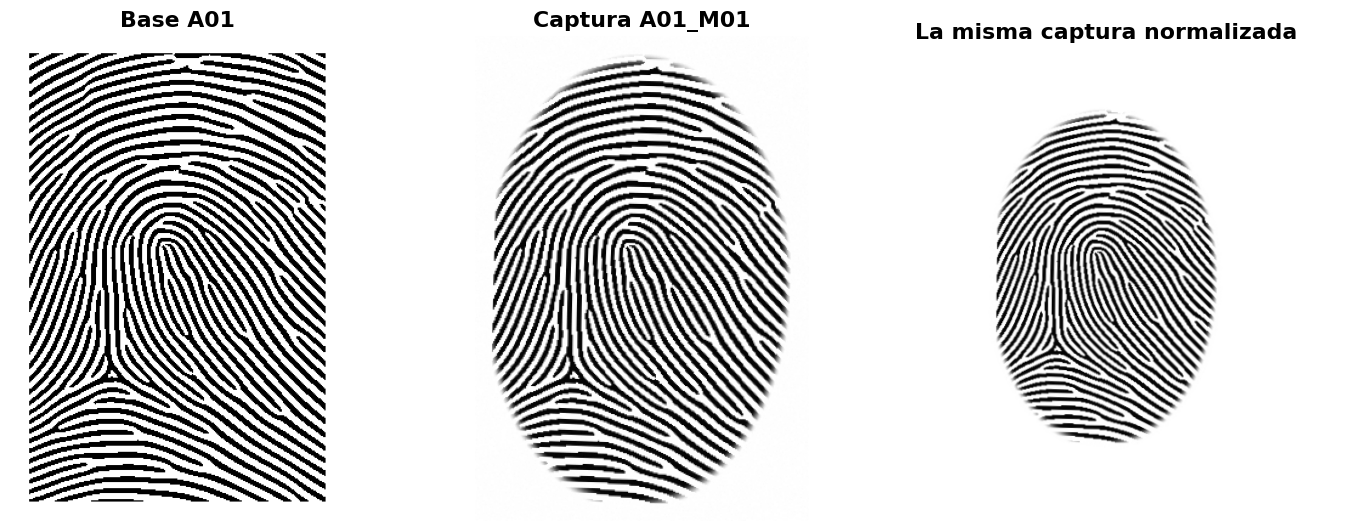

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(13, 5))
for a, archivo, titulo in zip(ax,
        ["base_A01.png", "captura_original.png", "huella_normalizada.png"],
        ["Base A01", "Captura A01_M01", "La misma captura normalizada"]):
    a.imshow(plt.imread(FIGURAS / archivo), cmap="gray")
    a.set_title(titulo); a.axis("off")
plt.tight_layout(); plt.show()

**Lectura de la figura.** Son imágenes reales del desarrollo. La base no es una consulta ya preparada. La captura incorpora el procedimiento de generación; la normalizada intenta reducir cambios geométricos. No se ha reconstruido una cresta faltante ni convertido la captura en una copia de la base.

## Para qué separamos entrenamiento, validación y prueba

Entrenamiento es el material con el que construimos la representación aprendida y los modelos. Validación permite comparar decisiones y calibrar parámetros. Prueba final debe quedar fuera hasta fijar el procedimiento que se quiere evaluar.

El conjunto anterior llegó a 220 capturas: 120 autorizadas de entrenamiento, 50 de validación (30 autorizadas y 20 intrusas) y 50 de prueba (30 autorizadas y 20 intrusas). La ampliación con Anguli se explica en el segundo cuaderno. No cambia retrospectivamente el significado de los resultados anteriores.

**Fuga de información** es utilizar datos que debían quedar fuera para tomar decisiones del modelo. También ocurre si calculamos escalas, seleccionamos características o elegimos un umbral con esos datos: no se limita a entrenar K-means.

Como las capturas provienen de unas pocas bases sintéticas, muchas comparten estructura. Separar capturas no demuestra generalización a nuevos dedos ni a biometría real. Sí permite estudiar el problema concreto de reconocer capturas de las identidades autorizadas conocidas.

,Autorizadas,Intrusas
Partición,,
Entrenamiento,120,0
Validación,30,20
Prueba reservada,30,20


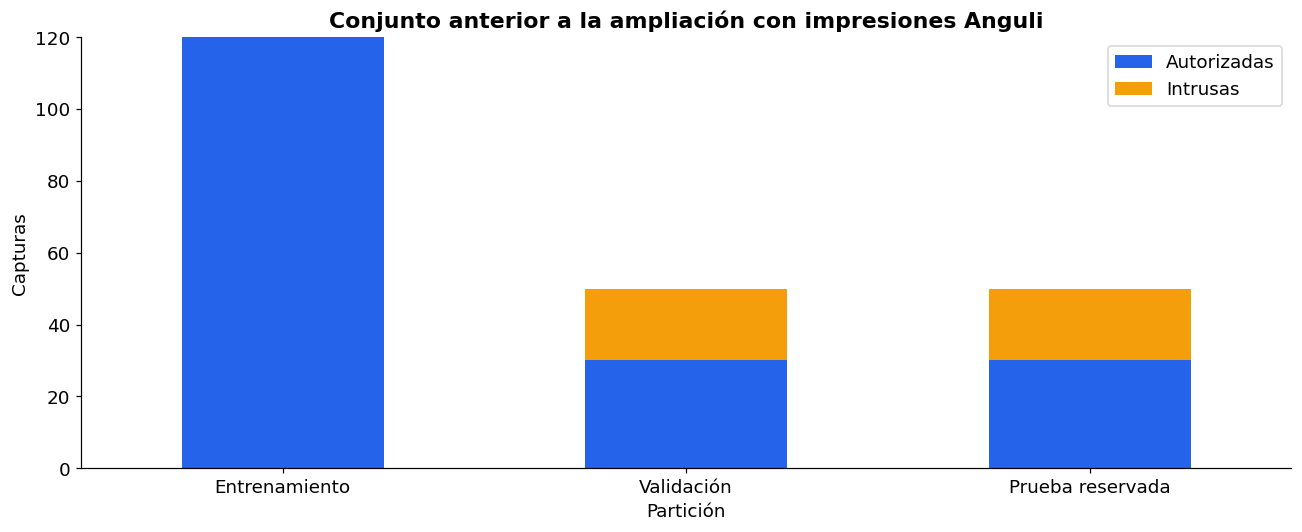

In [5]:
tabla = pd.DataFrame({"Partición": ["Entrenamiento", "Validación", "Prueba reservada"],
    "Autorizadas": [120, 30, 30], "Intrusas": [0, 20, 20]}).set_index("Partición")
display(tabla)
tabla.plot.bar(stacked=True, color=["#2563EB", "#F59E0B"], rot=0)
plt.ylabel("Capturas"); plt.title("Conjunto anterior a la ampliación con impresiones Anguli")
plt.tight_layout(); plt.show()

## Normalización geométrica: comparar entradas en condiciones más parecidas

Si una huella está corrida o girada, una parte de la diferencia entre imágenes se debe a la toma, no a la identidad. Nuestro procedimiento detecta la región de huella, separa fondo mediante una máscara, estima el eje mayor del contorno, gira y centra la imagen en un lienzo de 512 × 512.

La **máscara** indica qué píxeles se consideran parte útil de la huella. Su forma también ayuda a estimar la orientación. No usamos la etiqueta ni el ángulo conocido de generación para corregir la imagen.

Se conserva la escala de las crestas en píxeles; no se estira cada huella para llenar el marco. Un contorno casi circular da una orientación poco fiable. Además, un eje no distingue su sentido: la huella puede quedar girada 180°. Eso motivó un descriptor que agrupa cuadrantes opuestos.

No aplicamos en esta normalización final todos los métodos que existen en visión artificial. No hay extracción explícita de minucias, esqueletización ni una red neuronal. La consigna ofrece técnicas posibles; nosotros elegimos un recorrido coherente con los datos y lo documentamos.

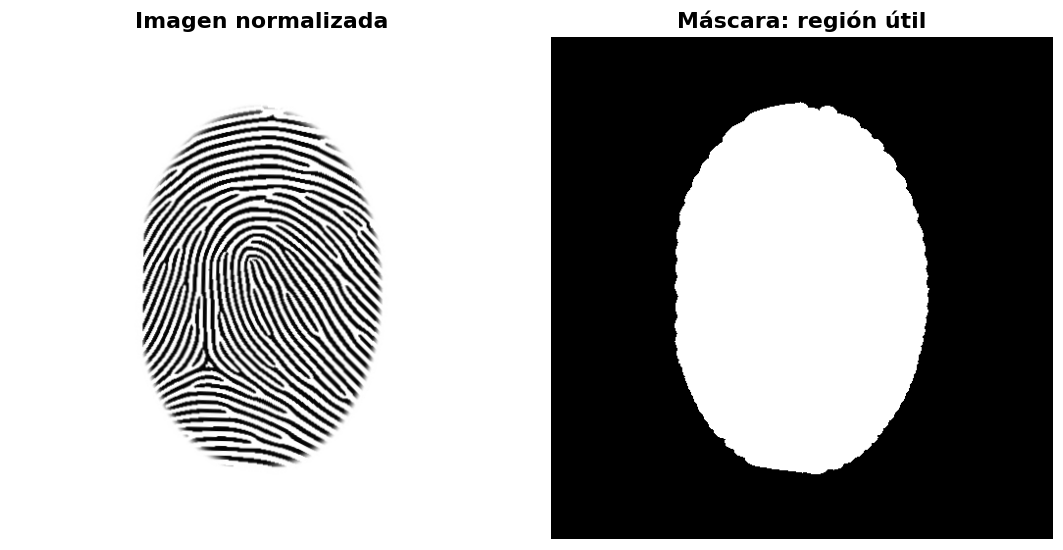

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
for a, archivo, titulo in zip(ax, ["huella_normalizada.png", "mascara.png"],
                             ["Imagen normalizada", "Máscara: región útil"]):
    a.imshow(plt.imread(FIGURAS / archivo), cmap="gray"); a.set_title(titulo); a.axis("off")
plt.tight_layout(); plt.show()

## GLCM: describir textura sin comparar todos los píxeles

GLCM significa matriz de coocurrencia de niveles de gris. Cuenta cuántas veces un nivel de gris aparece junto a otro a una distancia y orientación elegidas. Después normalizamos los conteos para describir su frecuencia relativa.

Imaginemos una imagen muy alternada entre oscuro y claro: tendrá muchos pares con valores diferentes. Una zona uniforme tendrá más pares de valores parecidos. La matriz permite resumir ese comportamiento, que está relacionado con la textura.

Nuestro extractor acondiciona el contraste dentro de la región útil y cuantiza en 16 niveles. Erosiona el borde de la máscara para reducir la influencia de la frontera con el fondo. Esto es parte del descriptor, posterior a la normalización geométrica.

| Medida | Interpretación sencilla |
|---|---|
| Contraste | Cuánto difieren los niveles de los pares de píxeles |
| Homogeneidad | Cuánto se concentran los pares en valores parecidos |
| Energía | Cuánto se concentran las frecuencias en ciertas combinaciones |
| Correlación | Qué relación estadística hay entre los valores de cada par |

Energía GLCM no significa energía eléctrica ni energía de audio. Cada medida tiene un significado dentro de su representación.

### De dónde salen exactamente las 144 características

Se utilizan tres bloques: toda la región, la combinación de los cuadrantes noroeste–sudeste y la combinación noreste–sudoeste. Se cuentan pares dentro de cada cuadrante y se suman los conteos de los opuestos; no se conectan artificialmente píxeles de un cuadrante con otro.

$$\boxed{3\text{ bloques}\times3\text{ distancias}\times4\text{ orientaciones}\times4\text{ medidas}=144}$$

Las distancias nominales son 1, 3 y 5 píxeles; las orientaciones, 0°, 45°, 90° y 135°. **No son nueve distancias.** El agrupamiento de cuadrantes opuestos y la simetrización de conteos atienden la ambigüedad de 180°. No eliminan cualquier diferencia debida a deformaciones o rotaciones arbitrarias.

El descriptor caracteriza textura. No localiza individualmente terminaciones y bifurcaciones de crestas como lo haría un método de minucias. Esa elección tiene ventajas de sencillez y límites de discriminación.

In [7]:
paquete = np.load(DATOS / "huellas_desarrollo.npz")
X = paquete["X"]
meta = pd.read_csv(DATOS / "huellas_catalogo.csv")
display(pd.DataFrame({"Característica": paquete["nombres"][:12],
                      "Valor de A01_M01": X[0, :12]}).round(5))

,Característica,Valor de A01_M01
0,global_d1_a0_contraste,0.05886
1,global_d1_a0_homogeneidad,0.56741
2,global_d1_a0_energia,0.32096
3,global_d1_a0_correlacion,0.83614
4,global_d1_a45_contraste,0.08606
5,global_d1_a45_homogeneidad,0.56517
6,global_d1_a45_energia,0.30462
7,global_d1_a45_correlacion,0.76049
8,global_d1_a90_contraste,0.06566
9,global_d1_a90_homogeneidad,0.54084


## Cómo construimos el dataset de voz

Se registraron los comandos reconocer, identificar y salir de seis hablantes, identificados anónimamente como H001–H006. La captura permite elegir persona, sesión y palabra; mostrar cuenta regresiva; grabar; escuchar y guardar o repetir. Una sesión representa una tanda de grabaciones bajo unas condiciones, no una clase nueva.

Quedaron 180 originales. Tras la revisión se conservan 179 y una muestra permanece excluida con motivo documentado. Hay 60 identificar, 60 reconocer y 59 salir. No se borraron todas las tomas con avisos: un aviso automático requiere interpretación y no demuestra por sí solo que una muestra sea inútil.

La captura no se publica ni se incorpora al entrenamiento por el solo hecho de usar la interfaz final. Reunir datos y consultar el modelo son operaciones diferentes.

## Preprocesamiento de audio

La versión común convierte a mono cuando corresponde, remuestrea a 16 kHz, quita el desplazamiento medio y estima la actividad mediante energía en ventanas. Recorta silencios externos con márgenes y controla la amplitud sin amplificar ilimitadamente.

En la configuración documentada se usan ventanas de 20 ms con salto de 10 ms para actividad, márgenes de 150 ms, pico objetivo 0,8 y ganancia máxima de 6 dB. Los umbrales combinan límites de nivel y contraste con el ruido estimado. Son decisiones del procedimiento, no valores universales para cualquier micrófono.

Normalizar amplitud no repara saturación: si la señal ya perdió sus picos durante la captura, reducirla no recupera lo perdido. Del mismo modo, detectar energía no demuestra que haya una palabra válida. Una respiración o ruido puede superar un umbral.

No se acelera ni se estira la palabra para imponer una duración única. Los originales y procesados se conservan separados.

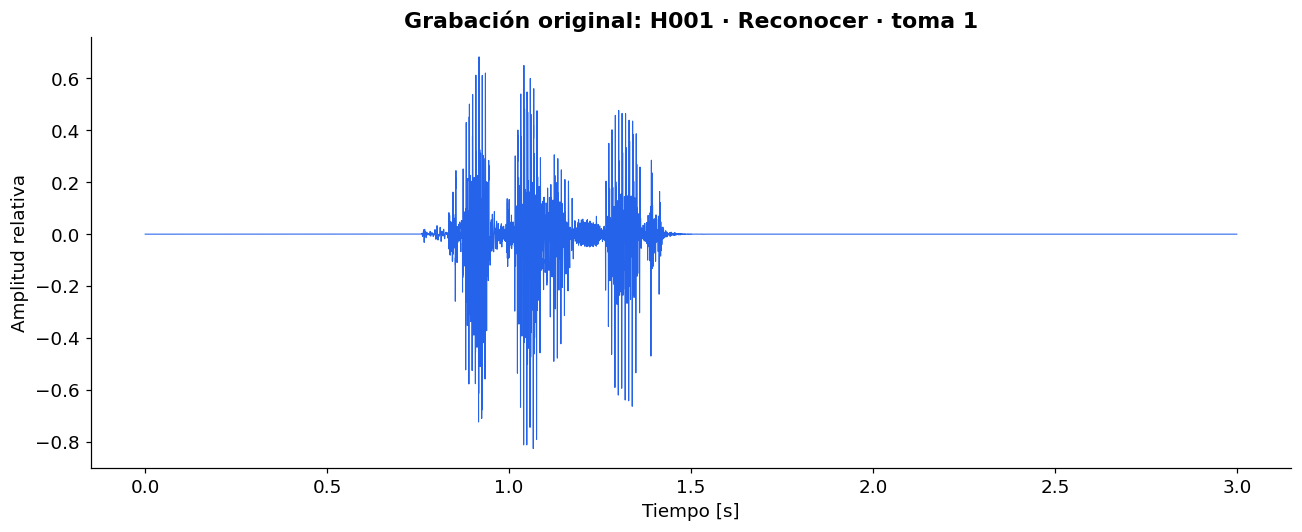

In [8]:
audio = np.load(DATOS / "audio_ejemplo.npz")
y, fs = audio["y"], int(audio["fs"])
t = np.arange(len(y)) / fs
plt.plot(t, y, color="#2563EB", linewidth=0.7)
plt.xlabel("Tiempo [s]"); plt.ylabel("Amplitud relativa")
plt.title("Grabación original: H001 · Reconocer · toma 1")
plt.tight_layout(); plt.show()

**Cómo leerla.** El eje horizontal es tiempo; el vertical es amplitud instantánea. La alternancia de signos es normal. Las zonas con mayor oscilación sugieren actividad, pero la forma de onda no equivale a una transcripción. Este gráfico usa una grabación real publicada; no se usa para ajustar nuevos umbrales.

## Del sonido a 160 números

Para extraer características analizamos ventanas de 25 ms, con un salto de 10 ms. Estas ventanas no son los mismos parámetros de detección de actividad. Una ventana describe un fragmento breve; los diez segmentos relativos organizan el comienzo, desarrollo y final de la palabra.

Se calculan cruces por cero (ZCR), amplitud absoluta y MFCC. ZCR mide cambios de signo. La amplitud describe nivel. Los MFCC resumen la distribución de energía en frecuencia: se calcula espectro, se agrupa mediante filtros Mel, se aplica logaritmo y una transformada que produce coeficientes. No son palabras ni frecuencias individuales.

Se conservan c1, c2, c4 y c5. Por cada segmento se incluyen dos resúmenes de ZCR, dos de amplitud y media, máximo y desviación de cada uno de esos cuatro MFCC:

$$\boxed{10\,[2+2+4(3)]=160}$$

Con este procedimiento, una palabra de 0,7 s y otra de 1 s generan la misma cantidad de características sin cambiar su velocidad. No garantiza que las sílabas queden perfectamente alineadas.

**Hay dos desviaciones diferentes:** la desviación MFCC incluida en el vector describe variaciones dentro de un segmento de un audio. La desviación entre grabaciones de una columna describe cuánto varía esa característica de una muestra a otra. No hay que confundirlas.

## Estudio estadístico: qué buscamos antes de clasificar

Para cada característica y clase calculamos su media y desviación entre muestras. La media representa el centro; la desviación, cuánto se separan los valores respecto de él. La media ± una desviación no contiene necesariamente todos los datos y no es un intervalo de confianza.

Nos interesa que las diferencias entre clases sean relevantes frente a la variación dentro de cada clase. No existe una media general útil que mezcle las 144 características de huella o las 160 de audio como si midieran lo mismo.

Para ordenar columnas usamos una relación entre variación entre clases y variación interna. Es un diagnóstico; una desviación alta, por sí sola, no justifica quitar una característica. El siguiente gráfico compara dos columnas reales en entrenamiento, con todos sus puntos y media ± desviación muestral. Elige el mayor y menor valor finito del indicador para mostrar dos extremos, no para prometer que una columna aislada clasifica perfectamente.

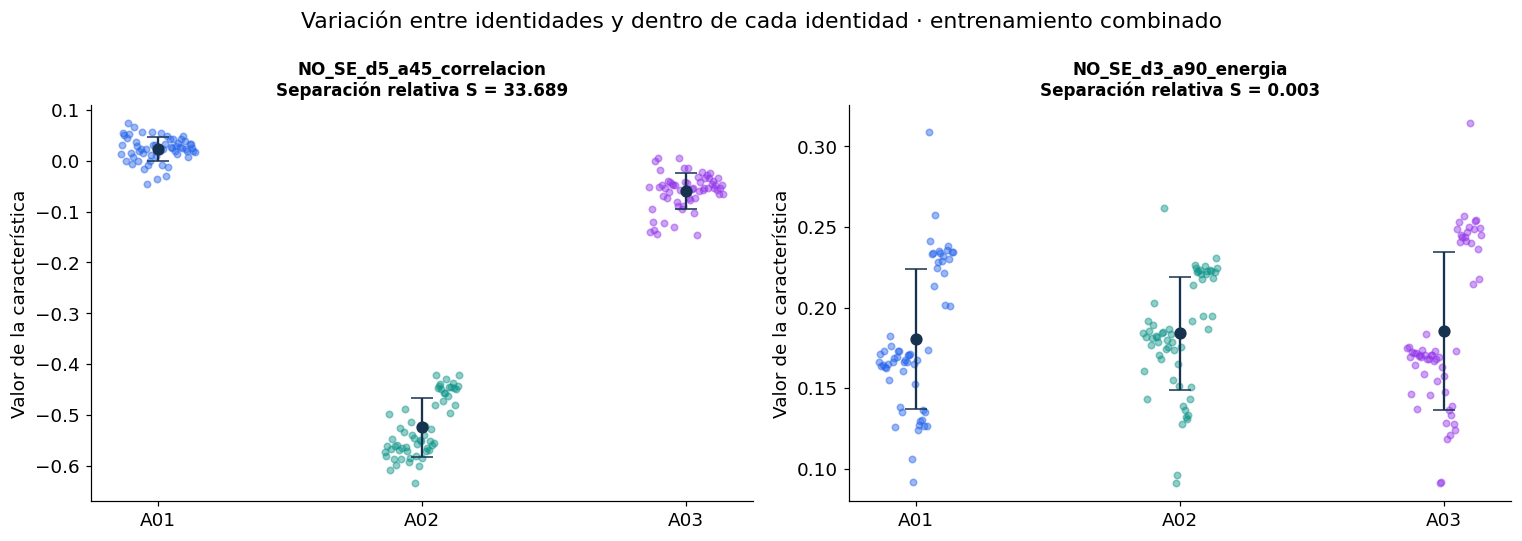

In [9]:
train = meta["particion"].eq("entrenamiento").to_numpy()
xt, yt = X[train], meta.loc[train, "identidad"].to_numpy()
media = xt.mean(axis=0)
entre = sum((yt == c).sum() * (xt[yt == c].mean(axis=0) - media)**2 for c in np.unique(yt))
dentro = sum(((xt[yt == c] - xt[yt == c].mean(axis=0))**2).sum(axis=0) for c in np.unique(yt))
score = np.divide(entre, dentro, out=np.full_like(entre, np.nan), where=dentro > 0)
orden = np.argsort(np.nan_to_num(score, nan=-np.inf))
columnas = [orden[-1], orden[0]]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, j in zip(axes, columnas):
    for i, identidad in enumerate(["A01", "A02", "A03"]):
        valores = xt[yt == identidad, j]
        ax.scatter(i + np.linspace(-0.14, 0.14, len(valores)), valores,
                   s=18, alpha=0.45, color=COLORES[identidad])
        ax.errorbar(i, valores.mean(), yerr=valores.std(ddof=1), fmt="o",
                    color="#16324F", capsize=7, markersize=7)
    ax.set_xticks([0, 1, 2], ["A01", "A02", "A03"])
    ax.set_title(f"{paquete['nombres'][j]}\nSeparación relativa S = {score[j]:.3f}", fontsize=11)
    ax.set_ylabel("Valor de la característica")
plt.suptitle("Variación entre identidades y dentro de cada identidad · entrenamiento combinado")
plt.tight_layout(); plt.show()

La figura no compara directamente la altura numérica de ambos paneles: sus columnas tienen escalas distintas. La elección del modelo debe considerar la combinación de características y evaluarse con datos apartados del ajuste.

## Lo que debemos llevar al próximo cuaderno

Ya tenemos dos matrices, con filas que representan muestras y columnas con significado estable. Sus etiquetas y particiones se guardan aparte. Esas etiquetas permiten evaluar y, en una etapa específica de huellas, seleccionar columnas. No se incorporan al vector como números.

Ahora necesitamos estudiar la distribución de esos puntos, agrupar huellas y decidir si una consulta está suficientemente cerca de alguna identidad autorizada. Esa es la función del segundo cuaderno.

## Fuentes y alcance de esta guía

Texto didáctico basado en la consigna **Trabajo Final 2026**, la presentación **Clase 9 — Aprendizaje 2026** del material de cátedra y los archivos del proyecto que se enlazan debajo. El detalle del descriptor acústico sigue la implementación y su documentación, que remite a Clase 10 — Percepción; esa presentación no estaba incluida en el ZIP consultado. Los ejemplos hipotéticos se identifican como tales.

Versión del repositorio consultada: `eb97d38ab95d1f3a776734b2b2fa36ed54df37b9`, 24/10/2026. Las cifras describen esa versión, no garantizan otras condiciones.

- [documentos/etapas/normalizacion_final.md](https://github.com/peterortiz03/Trabajo-Final-IA1/blob/eb97d38ab95d1f3a776734b2b2fa36ed54df37b9/documentos/etapas/normalizacion_final.md)
- [documentos/etapas/caracteristicas_huellas_hito1.md](https://github.com/peterortiz03/Trabajo-Final-IA1/blob/eb97d38ab95d1f3a776734b2b2fa36ed54df37b9/documentos/etapas/caracteristicas_huellas_hito1.md)
- [documentos/etapas/caracteristicas_audio_hito2.md](https://github.com/peterortiz03/Trabajo-Final-IA1/blob/eb97d38ab95d1f3a776734b2b2fa36ed54df37b9/documentos/etapas/caracteristicas_audio_hito2.md)
- [documentos/etapas/verificacion_estadistica.md](https://github.com/peterortiz03/Trabajo-Final-IA1/blob/eb97d38ab95d1f3a776734b2b2fa36ed54df37b9/documentos/etapas/verificacion_estadistica.md)
- [config/caracteristicas_huellas_glcm_v1.json](https://github.com/peterortiz03/Trabajo-Final-IA1/blob/eb97d38ab95d1f3a776734b2b2fa36ed54df37b9/config/caracteristicas_huellas_glcm_v1.json)